In [1]:
!pip install torchtext==0.4.0 -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.1/53.1 kB 2.5 MB/s eta 0:00:00


In [2]:
from torchtext import data, datasets
import torch
# For tokenization
TEXT = data.Field(tokenize='spacy',
                  tokenizer_language='en_core_web_sm',
                  include_lengths = True)
# For multi-class classification labels
LABEL = data.LabelField()
# Load the TREC dataset
# train_data, test_data = datasets.TREC.splits(TEXT, LABEL, fine_grained=False)
train_data, test_data = datasets.TREC.splits(TEXT, LABEL, fine_grained=False)

downloading train_5500.label


train_5500.label: 100%|██████████| 336k/336k [00:00<00:00, 1.17MB/s]


downloading TREC_10.label


TREC_10.label: 100%|██████████| 23.4k/23.4k [00:00<00:00, 331kB/s]


In [3]:
TEXT.build_vocab(train_data,
                max_size=25000,
                vectors="glove.6B.100d",
                # min_freq=3,
                unk_init=torch.Tensor.normal_)
LABEL.build_vocab(train_data)

.vector_cache/glove.6B.zip: 862MB [02:39, 5.41MB/s]                           
100%|█████████▉| 399999/400000 [00:19<00:00, 20492.35it/s]


Using device: cuda

Vocab size: 9330
Classes: 6
Embedding dim: 100

TRAINING BiLSTM
Epoch 01 | Train Loss: 1.248 Acc: 48.06% | Valid Loss: 0.920 Acc: 65.60%
Epoch 02 | Train Loss: 0.855 Acc: 68.00% | Valid Loss: 0.708 Acc: 74.50%
Epoch 03 | Train Loss: 0.715 Acc: 73.40% | Valid Loss: 0.629 Acc: 76.54%
Epoch 04 | Train Loss: 0.632 Acc: 76.72% | Valid Loss: 0.570 Acc: 78.70%
Epoch 05 | Train Loss: 0.560 Acc: 79.47% | Valid Loss: 0.502 Acc: 82.00%
Epoch 06 | Train Loss: 0.477 Acc: 83.15% | Valid Loss: 0.491 Acc: 82.08%
Epoch 07 | Train Loss: 0.432 Acc: 84.48% | Valid Loss: 0.457 Acc: 83.02%
Epoch 08 | Train Loss: 0.375 Acc: 86.58% | Valid Loss: 0.426 Acc: 84.67%
Epoch 09 | Train Loss: 0.324 Acc: 88.82% | Valid Loss: 0.431 Acc: 85.22%
Epoch 10 | Train Loss: 0.294 Acc: 89.77% | Valid Loss: 0.451 Acc: 84.00%
Epoch 11 | Train Loss: 0.272 Acc: 90.42% | Valid Loss: 0.413 Acc: 85.19%
Epoch 12 | Train Loss: 0.228 Acc: 92.15% | Valid Loss: 0.430 Acc: 85.96%
Epoch 13 | Train Loss: 0.208 Acc: 92.64%

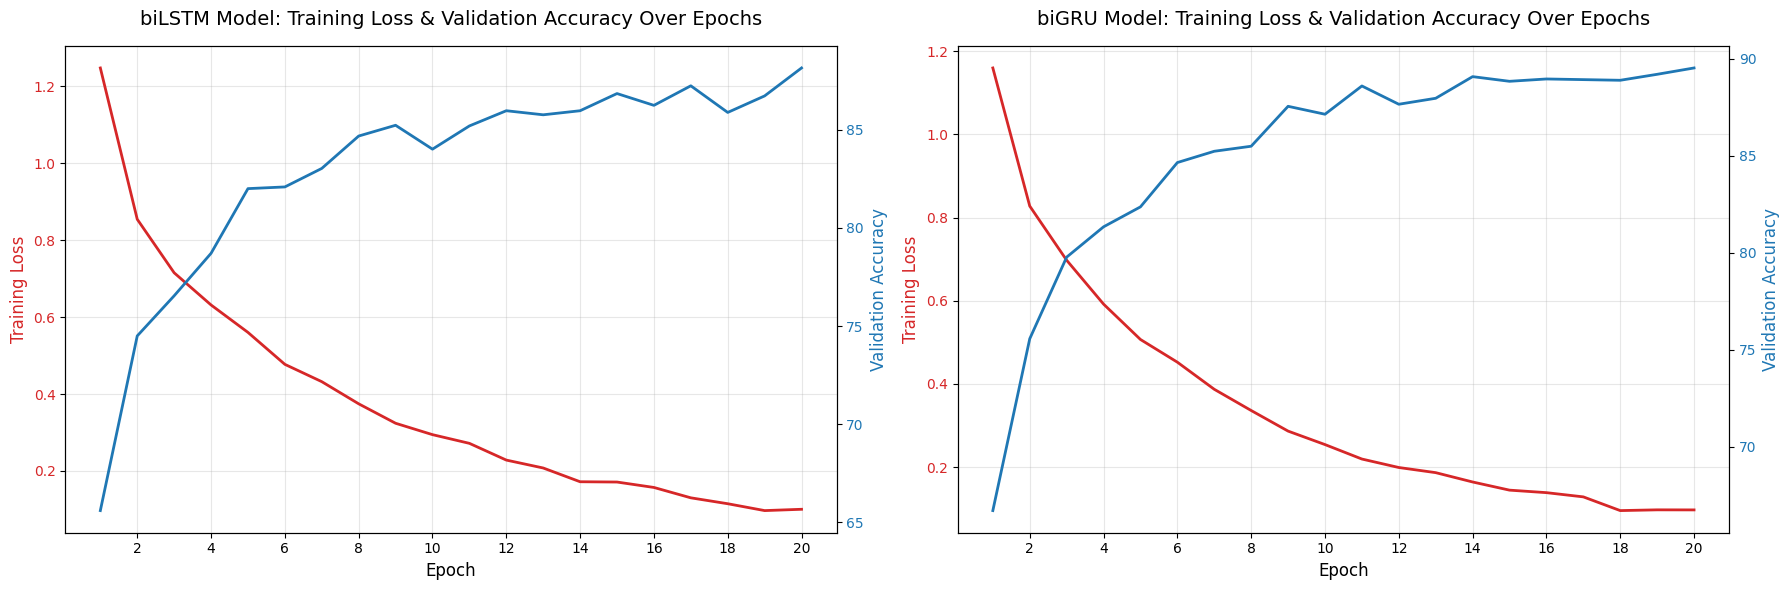

PART 3(a) COMPLETE!


In [5]:
# ============================================================================
# PART 3(a): BiLSTM and BiGRU - SIDE BY SIDE WITH DUAL Y-AXES
# ============================================================================

import torch
import torch.nn as nn
import torch.optim as optim
from torchtext import data
import numpy as np
import matplotlib.pyplot as plt
import random

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}\n')

# Config
BATCH_SIZE = 64
N_EPOCHS = 20
LEARNING_RATE = 1e-3
HIDDEN_DIM = 256
N_LAYERS = 2
DROPOUT = 0.5
GRAD_CLIP = 1.0

# split train and validation data
train_data, valid_data = train_data.split(split_ratio=0.85, random_state=random.seed(42))

# Create iterators
train_iterator, valid_iterator, test_iterator = data.BucketIterator.splits(
    (train_data, valid_data, test_data),
    batch_size=BATCH_SIZE,
    sort_within_batch=True,
    sort_key=lambda x: len(x.text),
    device=device
)

# Get embeddings
vocab_size = len(TEXT.vocab)
output_size = len(LABEL.vocab)
embedding_dim = TEXT.vocab.vectors.size(1)
pretrained_embeddings = TEXT.vocab.vectors
PAD_IDX = TEXT.vocab.stoi[TEXT.pad_token]
UNK_IDX = TEXT.vocab.stoi[TEXT.unk_token]

print(f"Vocab size: {vocab_size}")
print(f"Classes: {output_size}")
print(f"Embedding dim: {embedding_dim}\n")

# Helper functions
def categorical_accuracy(preds, y):
    top_pred = preds.argmax(1)
    correct = top_pred.eq(y).sum().item()
    return correct / y.size(0)

def train_epoch(model, iterator, optimizer, criterion):
    model.train()
    epoch_loss = 0
    epoch_acc = 0

    for batch in iterator:
        text, text_lengths = batch.text
        if text.dim() == 2 and text.size(0) != text_lengths.size(0):
            text = text.transpose(0, 1)
        labels = batch.label.long().to(device)

        optimizer.zero_grad()
        predictions = model(text, text_lengths)
        loss = criterion(predictions, labels)
        acc = categorical_accuracy(predictions, labels)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()

        epoch_loss += loss.item()
        epoch_acc += acc

    return epoch_loss / len(iterator), epoch_acc / len(iterator)

def evaluate(model, iterator, criterion):
    model.eval()
    epoch_loss = 0
    epoch_acc = 0

    with torch.no_grad():
        for batch in iterator:
            text, text_lengths = batch.text
            if text.dim() == 2 and text.size(0) != text_lengths.size(0):
                text = text.transpose(0, 1)
            labels = batch.label.long().to(device)

            predictions = model(text, text_lengths)
            loss = criterion(predictions, labels)
            acc = categorical_accuracy(predictions, labels)

            epoch_loss += loss.item()
            epoch_acc += acc

    return epoch_loss / len(iterator), epoch_acc / len(iterator)

# ============================================================================
# BiLSTM MODEL
# ============================================================================
print("="*80)
print("TRAINING BiLSTM")
print("="*80)

class BiLSTM(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers, bidirectional, dropout, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, num_layers=n_layers, bidirectional=bidirectional,
                           dropout=dropout if n_layers > 1 else 0, batch_first=True)
        self.fc = nn.Linear(hidden_dim * 2 if bidirectional else hidden_dim, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, text, text_lengths):
        embedded = self.dropout(self.embedding(text))
        lengths = text_lengths.clamp(min=1, max=embedded.size(1)).cpu().to(torch.int64)
        packed = nn.utils.rnn.pack_padded_sequence(embedded, lengths, batch_first=True, enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        if self.lstm.bidirectional:
            hidden = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        else:
            hidden = hidden[-1,:,:]
        return self.fc(self.dropout(hidden))

# Train BiLSTM
bilstm_model = BiLSTM(vocab_size, embedding_dim, HIDDEN_DIM, output_size, N_LAYERS, True, DROPOUT, PAD_IDX)
bilstm_model.embedding.weight.data.copy_(pretrained_embeddings)
bilstm_model.embedding.weight.data[UNK_IDX] = torch.zeros(embedding_dim)
bilstm_model.embedding.weight.data[PAD_IDX] = torch.zeros(embedding_dim)
bilstm_model = bilstm_model.to(device)

optimizer = optim.Adam(bilstm_model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss().to(device)

best_valid_acc = 0
bilstm_train_losses, bilstm_valid_accs = [], []

for epoch in range(N_EPOCHS):
    train_loss, train_acc = train_epoch(bilstm_model, train_iterator, optimizer, criterion)
    valid_loss, valid_acc = evaluate(bilstm_model, valid_iterator, criterion)
    bilstm_train_losses.append(train_loss)
    bilstm_valid_accs.append(valid_acc * 100)
    if valid_acc > best_valid_acc:
        best_valid_acc = valid_acc
        torch.save(bilstm_model.state_dict(), 'bilstm_model.pt')
    print(f'Epoch {epoch+1:02} | Train Loss: {train_loss:.3f} Acc: {train_acc*100:.2f}% | Valid Loss: {valid_loss:.3f} Acc: {valid_acc*100:.2f}%')

bilstm_model.load_state_dict(torch.load('bilstm_model.pt'))
test_loss, test_acc = evaluate(bilstm_model, test_iterator, criterion)

print(f'\n{"="*80}')
print(f'---- Loading best biLSTM model for final test evaluation ----')
print(f'\nFinal biLSTM Test Loss: {test_loss:.3f} | Final biLSTM Test Accuracy: {test_acc*100:.2f}%')
print(f'Final biLSTM Test Accuracy: {test_acc*100:.2f}%')
print(f'{"="*80}\n')

# ============================================================================
# BiGRU MODEL
# ============================================================================
print("="*80)
print("TRAINING BiGRU")
print("="*80)

class BiGRU(nn.Module):
    def __init__(self, vocab_size, embedding_dim, hidden_dim, output_dim, n_layers, bidirectional, dropout, pad_idx):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.gru = nn.GRU(embedding_dim, hidden_dim, num_layers=n_layers, bidirectional=bidirectional,
                         dropout=dropout if n_layers > 1 else 0, batch_first=True)
        self.fc = nn.Linear(hidden_dim * 2 if bidirectional else hidden_dim, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, text, text_lengths):
        embedded = self.dropout(self.embedding(text))
        lengths = text_lengths.clamp(min=1).cpu().to(torch.int64)
        packed = nn.utils.rnn.pack_padded_sequence(embedded, lengths, batch_first=True, enforce_sorted=False)
        _, hidden = self.gru(packed)
        if self.gru.bidirectional:
            hidden = torch.cat((hidden[-2,:,:], hidden[-1,:,:]), dim=1)
        else:
            hidden = hidden[-1,:,:]
        return self.fc(self.dropout(hidden))

# Train BiGRU
bigru_model = BiGRU(vocab_size, embedding_dim, HIDDEN_DIM, output_size, N_LAYERS, True, DROPOUT, PAD_IDX)
bigru_model.embedding.weight.data.copy_(pretrained_embeddings)
bigru_model.embedding.weight.data[UNK_IDX] = torch.zeros(embedding_dim)
bigru_model.embedding.weight.data[PAD_IDX] = torch.zeros(embedding_dim)
bigru_model = bigru_model.to(device)

optimizer = optim.Adam(bigru_model.parameters(), lr=LEARNING_RATE)

best_valid_acc = 0
bigru_train_losses, bigru_valid_accs = [], []

for epoch in range(N_EPOCHS):
    train_loss, train_acc = train_epoch(bigru_model, train_iterator, optimizer, criterion)
    valid_loss, valid_acc = evaluate(bigru_model, valid_iterator, criterion)
    bigru_train_losses.append(train_loss)
    bigru_valid_accs.append(valid_acc * 100)
    if valid_acc > best_valid_acc:
        best_valid_acc = valid_acc
        torch.save(bigru_model.state_dict(), 'bigru_model.pt')
    print(f'Epoch {epoch+1:02} | Train Loss: {train_loss:.3f} Acc: {train_acc*100:.2f}% | Valid Loss: {valid_loss:.3f} Acc: {valid_acc*100:.2f}%')

bigru_model.load_state_dict(torch.load('bigru_model.pt'))
test_loss, test_acc = evaluate(bigru_model, test_iterator, criterion)

print(f'\n{"="*80}')
print(f'---- Loading best biGRU model for final test evaluation ----')
print(f'\nFinal biGRU Test Loss: {test_loss:.3f} | Final biGRU Test Accuracy: {test_acc*100:.2f}%')
print(f'Final biGRU Test Accuracy: {test_acc*100:.2f}%')
print(f'{"="*80}\n')

# ============================================================================
# PLOT BOTH SIDE BY SIDE (1x2 SUBPLOTS WITH DUAL Y-AXES)
# ============================================================================
epochs = list(range(1, N_EPOCHS+1))

fig, (ax1, ax3) = plt.subplots(1, 2, figsize=(18, 6))

# --- LEFT PLOT: BiLSTM ---
color_loss = 'tab:red'
ax1.set_xlabel('Epoch', fontsize=12)
ax1.set_ylabel('Training Loss', color=color_loss, fontsize=12)
ax1.plot(epochs, bilstm_train_losses, color=color_loss, linewidth=2)
ax1.tick_params(axis='y', labelcolor=color_loss)
ax1.set_xticks(epochs[1::2])
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
color_acc = 'tab:blue'
ax2.set_ylabel('Validation Accuracy', color=color_acc, fontsize=12)
ax2.plot(epochs, bilstm_valid_accs, color=color_acc, linewidth=2)
ax2.tick_params(axis='y', labelcolor=color_acc)

ax1.set_title('biLSTM Model: Training Loss & Validation Accuracy Over Epochs', fontsize=14, pad=15)

# --- RIGHT PLOT: BiGRU ---
color_loss = 'tab:red'
ax3.set_xlabel('Epoch', fontsize=12)
ax3.set_ylabel('Training Loss', color=color_loss, fontsize=12)
ax3.plot(epochs, bigru_train_losses, color=color_loss, linewidth=2)
ax3.tick_params(axis='y', labelcolor=color_loss)
ax3.set_xticks(epochs[1::2])
ax3.grid(True, alpha=0.3)

ax4 = ax3.twinx()
color_acc = 'tab:blue'
ax4.set_ylabel('Validation Accuracy', color=color_acc, fontsize=12)
ax4.plot(epochs, bigru_valid_accs, color=color_acc, linewidth=2)
ax4.tick_params(axis='y', labelcolor=color_acc)

ax3.set_title('biGRU Model: Training Loss & Validation Accuracy Over Epochs', fontsize=14, pad=15)

plt.tight_layout()
plt.savefig('bilstm_bigru_training_curves.png', dpi=300, bbox_inches='tight')
plt.show()

print("="*80)
print("PART 3(a) COMPLETE!")
print("="*80)